# Weighting intensity members by landfall

With `--land fine --intensity refit-basin`, our ERA5 run brings storms to the US Atlantic and Gulf
coasts about as often as observed, but the storms are too weak: 0.63 of the observed hurricane landfalls
([intensity.ipynb](intensity.ipynb), section 4). This notebook tests a correction applied after the
run. Each intensity member gets a weight so that first landfalls by zone and wind class come out at
the observed rates. The weights are fit on one half of 1981–2019 and checked on the other. [intensity.ipynb](intensity.ipynb)
describes the run, its 10 track realizations a year with 40 intensity members each, and
`ocr.risks.hurricane.validate`.

`ocr.risks.hurricane.reweight` finds each member's first landfall: the first hour in which its track
enters land from sea, on the 1/12° country raster that `validate` uses, with the member at 34 kt or
more. The landfall
has:

- a zone: the country if it is in `validate.COUNTRIES`, with the US split into TX–AL, FL,
  GA–Carolinas, VA–ME and the Pacific coast, and 'other land' for every other country
- a basin, from the landfall point
- a class, the member's wind there: 34–64, 64–96 or ≥96 kt

Each (zone, class) cell gets the weight (n_obs + k) / (chaz_expected + k). n_obs is the number of
observed first landfalls in the fit years, chaz_expected is CHAZ's number divided by its 400
members a year, and k = 2 keeps the weight of a cell with few events near 1. We chose k before
looking at any results. Members with no landfall at 34 kt weigh 1, and a member's weight applies to
everything it counts toward in `validate`. We test three zonings: country, country with other land
split by basin, and basin.

`reweight task` writes each member's first landfall and, for each (zone, basin, class) group, the
`validate` counts summed over its members. Any set of weights then gives a weighted `validate`
table without another pass over the tracks. Unweighted, the group sums reproduce the `validate`
tables exactly:


In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from ocr.risks.hurricane import reweight, store, validate

RUN = 'TCGI_CRH_PI-land-fine-intensity-refit-basin'
SOURCES = ('ibtracs', RUN)
HALVES = {'1981-1999': range(1981, 2000), '2000-2019': range(2000, 2020)}
SPLITS = {
    'fit 1981-1999, test 2000-2019': ('1981-1999', '2000-2019'),
    'fit 2000-2019, test 1981-1999': ('2000-2019', '1981-1999'),
}
LABEL = {
    'zone': 'country',
    'zone, other land by basin': 'country, other land by basin',
    'basin': 'basin',
}
US = [f'Atl+Gulf landfalls >= {t} kt' for t in (34, 64, 96)]
plt.rcParams.update(
    {'axes.spines.top': False, 'axes.spines.right': False, 'figure.dpi': 110, 'font.size': 9}
)

annual = {s: validate.load(s) for s in SOURCES}
records = {s: pd.read_parquet(store.path(reweight.keys(s)['records'])) for s in SOURCES}
grouped = {s: pd.read_parquet(store.path(reweight.keys(s)['grouped'])) for s in SOURCES}
members = {s: annual[s]['members'] for s in SOURCES}
obs, chaz = records['ibtracs'], records[RUN]


def weights(fit, scheme, k=reweight.K):
    return reweight.weights(chaz, obs, members[RUN], members['ibtracs'], HALVES[fit], scheme, k)


def tables(fit, k=reweight.K):
    out = {'IBTrACS': annual['ibtracs'], 'unweighted': annual[RUN]}
    for scheme in reweight.SCHEMES:
        out[LABEL[scheme]] = reweight.weighted_annual(
            grouped[RUN], weights(fit, scheme, k), scheme, members[RUN]
        )
    return out


for s in SOURCES:
    mine = reweight.weighted_annual(grouped[s], None, 'zone', members[s])
    cols = annual[s].columns.difference(['members'])
    diff = (mine[cols] - annual[s].loc[mine.index, cols]).abs().to_numpy().max()
    print(f'{s}: unweighted group sums against validate.annual, max |difference| {diff}')

m = validate.metrics({'IBTrACS': annual['ibtracs'], 'CHAZ': annual[RUN]}, range(1981, 2020)).loc[US]
print('US Atlantic and Gulf landfalls, CHAZ over IBTrACS, 1981-2019:')
print((m['CHAZ'] / m['IBTrACS']).round(2).to_string())

ibtracs: unweighted group sums against validate.annual, max |difference| 0.0
TCGI_CRH_PI-land-fine-intensity-refit-basin: unweighted group sums against validate.annual, max |difference| 0.0
US Atlantic and Gulf landfalls, CHAZ over IBTrACS, 1981-2019:
Atl+Gulf landfalls >= 34 kt    0.97
Atl+Gulf landfalls >= 64 kt    0.63
Atl+Gulf landfalls >= 96 kt    0.63


## 1. The weights

The table has the country-zone weights for the US zones, Cuba, Mexico and other land, fit on each
half. CHAZ makes too many weak first landfalls: at 34–64 kt the weight on other land is 0.37 and
0.48, and on Mexico 0.41 and 0.79. Some cells rest on a few events and change a lot between the
halves. TX–AL at 64–96 kt has a weight of 2.34 from 8 observed landfalls in 1981–1999, and 0.81 from
2 in 2000–2019.


In [2]:
shown = [
    z
    for z in weights('1981-1999', 'zone').index.get_level_values('key').unique()
    if z.startswith('USA') or z in ('CUB', 'MEX', 'other land')
]
w = pd.concat({f: weights(f, 'zone') for f in HALVES}, axis=1)
w = w[w.index.get_level_values('key').isin(shown)]
w.style.format('{:.2f}').set_caption(
    f"Country zones, k = {reweight.K:g}: observed first landfalls (n_obs) and CHAZ's at the "
    'observed member-years (chaz_expected) in each half, and the weight'
)

## 2. Held-out test

With weights fit on 1981–1999 and scored on 2000–2019, no zoning does clearly better than the
unweighted run. The
score is `validate.score`, the mean |ln(set / IBTrACS)| over 41 metrics (lower is better). It is
0.329 unweighted, against 0.334 with country zones, 0.319 with other land split by basin and 0.322
with basins. When the test years are resampled, the 90% range of
every paired difference spans zero. With weights fit on 2000–2019 and scored on 1981–1999, the score improves
from 0.433 to 0.382, 0.359 and 0.370, and every 90% range is below zero. US hurricane
landfalls do not improve on 1981–1999 (next table).

In [3]:
T = {split: tables(fit) for split, (fit, test) in SPLITS.items()}
rows = {}
for split, (fit, test) in SPLITS.items():
    rows[(split, 'test years')] = validate.score(validate.metrics(T[split], HALVES[test]))
    rows[(split, 'fit years')] = validate.score(validate.metrics(T[split], HALVES[fit]))
pd.DataFrame(rows).T.style.format('{:.3f}').set_caption(
    f'Mean |ln(source / IBTrACS)| over {len(validate.SCORED)} metrics (lower is better)'
)

In [4]:
rows = {}
for split, (fit, test) in SPLITS.items():
    b = validate.bootstrap(T[split], HALVES[test], n=2000, seed=0)
    for scheme in reweight.SCHEMES:
        d = b[LABEL[scheme]] - b['unweighted']
        rows[(split, LABEL[scheme])] = {
            'median': d.median(),
            '5%': d.quantile(0.05),
            '95%': d.quantile(0.95),
            'P(< 0)': (d < 0).mean(),
        }
pd.DataFrame(rows).T.style.format('{:+.3f}').set_caption(
    'Weighted minus unweighted score on the test years, 2,000 resamples of whole years '
    '(negative: weighting scores better)'
)

On the test years, US hurricane landfalls go from 0.79 to 1.08 of observed with country zones on
2000–2019, and from 0.47 to 0.45 on 1981–1999. Most of the 2000–2019 gain comes from the North
Atlantic scaling. `validate.metrics` scales North Atlantic quantities to the observed North Atlantic
storm count. The weights on weak first landfalls are below 1, so they cut CHAZ's North Atlantic
tropical storms on 2000–2019 from 15.41 to 12.20 a year, and the scaling factor rises from 1.04 to
1.32. Without the scaling, US hurricane landfalls go from 0.75 to 0.82 of observed on 2000–2019 and
from 0.56 to 0.44 on 1981–1999.

In [5]:
rows = {}
for split, (fit, test) in SPLITS.items():
    ys = list(HALVES[test])
    m = validate.metrics(T[split], ys).loc[US]
    rows[(split, 'scaled')] = m.drop(columns='IBTrACS').div(m['IBTrACS'], axis=0)
    raw = pd.DataFrame(
        {s: t.loc[ys, US].sum() / t.loc[ys, 'members'].sum() for s, t in T[split].items()}
    )
    rows[(split, 'not scaled')] = raw.drop(columns='IBTrACS').div(raw['IBTrACS'], axis=0)
pd.concat(rows).style.format('{:.2f}').set_caption(
    'US Atlantic and Gulf landfalls on the test years over IBTrACS, with and without the '
    'scaling to the observed North Atlantic storm count'
)

In [6]:
rows = {}
for split, (fit, test) in SPLITS.items():
    ys = list(HALVES[test])
    na = pd.Series(
        {s: t.loc[ys, 'NA TS'].sum() / t.loc[ys, 'members'].sum() for s, t in T[split].items()}
    )
    rows[split] = pd.DataFrame(
        {'NA tropical storms per yr': na, 'scaling factor': na['IBTrACS'] / na}
    )
pd.concat(rows).style.format('{:.2f}').set_caption(
    'North Atlantic storms reaching 34 kt on the test years, per member-year, and the factor '
    'validate.metrics multiplies North Atlantic quantities by'
)

Of the values of k from 0 to 10, none helps on both tests. With country zones, the 2000–2019 score falls as k rises, from
0.364 at k = 0 to 0.310 at k = 10, where the weights are close to 1. The 1981–1999 score rises, from
0.362 to 0.400.

In [7]:
rows = {}
for split, (fit, test) in SPLITS.items():
    for k in (0.0, 1.0, 2.0, 5.0, 10.0):
        rows[(split, f'{k:g}')] = validate.score(validate.metrics(tables(fit, k), HALVES[test]))
pd.DataFrame(rows).T.rename_axis(['split', 'k']).style.format('{:.3f}').set_caption(
    'Score on the test years by pseudo-count k'
)

## 3. First landfalls and sample size

About half of US hurricane landfalls are not first landfalls. Over 1981–2019, 0.529 of observed US Atlantic
and Gulf hurricane landfalls, and 0.513 of CHAZ's, come from storms (for CHAZ, members) whose
first landfall is in a US zone. The rest first came ashore on other land (0.294 and 0.314), in Cuba (0.098 and 0.103) or in
Mexico (0.078 and 0.071), and take those zones' weights. Other land's weights are all below 1, so they pull these landfalls down.

In [8]:
shares = {}
for s, lab in (('ibtracs', 'IBTrACS'), (RUN, 'CHAZ')):
    z = grouped[s].groupby('zone')['Atl+Gulf landfalls >= 64 kt'].sum()
    shares[lab] = z / z.sum()
shares = pd.DataFrame(shares).rename(index={reweight.NONE: '(none at 34 kt or more)'})
shares = shares[shares.max(axis=1) > 0.005].sort_values('IBTrACS', ascending=False)
shares.loc['all US zones'] = shares[shares.index.str.startswith('USA')].sum()
shares.style.format('{:.3f}').set_caption(
    'Share of US Atlantic and Gulf hurricane landfalls (64 kt), 1981-2019, by the zone of the '
    "member's first landfall"
)

,IBTrACS,CHAZ
zone,,
other land,0.294,0.314
USA TX-AL,0.235,0.156
USA GA-Car,0.157,0.126
CUB,0.098,0.103
USA FL,0.098,0.177
MEX,0.078,0.071
USA VA-ME,0.039,0.053
all US zones,0.529,0.513


Observed events are also few. Each half has 25 or 26 observed US hurricane landfalls, 2 and 5 of
them major, spread over four Atlantic and Gulf zones and two classes.

In [9]:
t = annual['ibtracs']
pd.DataFrame({h: t.loc[list(ys), US].sum() for h, ys in HALVES.items()}).style.format(
    '{:.0f}'
).set_caption('Observed US Atlantic and Gulf landfalls in each half')

,1981-1999,2000-2019
Atl+Gulf landfalls >= 34 kt,51,65
Atl+Gulf landfalls >= 64 kt,25,26
Atl+Gulf landfalls >= 96 kt,2,5


## 4. Storm counts in each half

Worldwide, CHAZ makes 84.81 storms reaching 34 kt per member-year in 1981–1999 and 103.89 in 2000–2019. IBTrACS has 86.47
and 86.45. In the North Atlantic both rise, CHAZ from 12.66 to 15.41 and IBTrACS from 10.58 to
16.05. Year by year, CHAZ's global count steps up around 1998–2000 and stays high, and IBTrACS has
no such step.

In [10]:
rows = {}
for s, lab in (('ibtracs', 'IBTrACS'), (RUN, 'CHAZ')):
    t = annual[s]
    for h, ys in HALVES.items():
        ys = list(ys)
        n = t.loc[ys, 'members'].sum()
        rows[(lab, h)] = {
            'global': t.loc[ys, 'TS formed global'].sum() / n,
            'North Atlantic': t.loc[ys, 'NA TS'].sum() / n,
        }
pd.DataFrame(rows).T.style.format('{:.2f}').set_caption(
    'Storms reaching 34 kt per year (CHAZ: per member-year)'
)

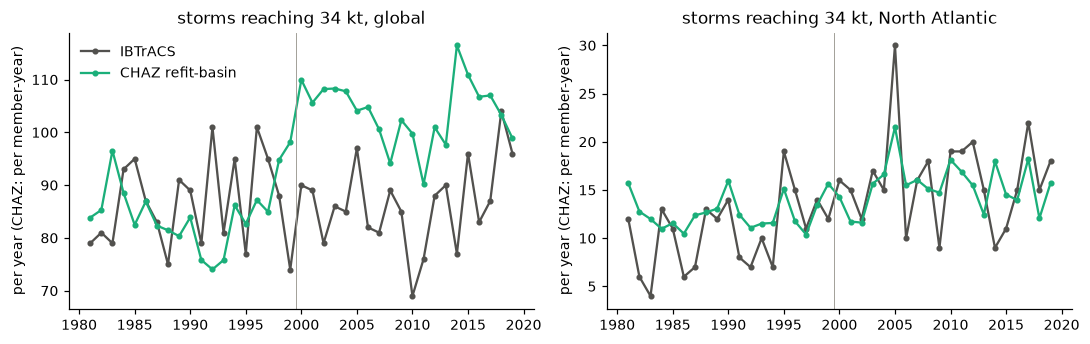

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
for ax, col, title in zip(axes, ('TS formed global', 'NA TS'), ('global', 'North Atlantic')):
    for s, lab, color in (('ibtracs', 'IBTrACS', '#52514e'), (RUN, 'CHAZ refit-basin', '#1baf7a')):
        t = annual[s]
        ax.plot(t.index, t[col] / t['members'], color=color, lw=1.5, marker='o', ms=3, label=lab)
    ax.axvline(1999.5, color='#9c9a92', lw=0.6)
    ax.set(title=f'storms reaching 34 kt, {title}', ylabel='per year (CHAZ: per member-year)')
axes[0].legend(frameon=False)
fig.tight_layout()

A weight fit on one half corrects that half's count error along with its intensity error, and
applies the same correction to the other half, whose count error is different. The same holds
for any test that fits on one half of 1981–2019 and scores on the other, including the test in
[intensity.ipynb](intensity.ipynb), section 5, that fits refit-basin on 1981–1999 only. CHAZ seeds storms in proportion to global
TCGI ([genesis-index.ipynb](genesis-index.ipynb), section 4), so the step most likely comes from
TCGI, but this notebook does not check it.

## Summary

Weighting members by the zone and class of their first landfall, fit on one half of 1981–2019, does
not bring US hurricane landfalls to the observed rate on the other half, and does not improve the
2000–2019 score beyond year-to-year noise. None of the runs in the notebooks uses it. A correction for the US would need to key on every US
landfall rather than only the first. About 25 observed US hurricane landfalls in each half are enough to fit
one factor for the whole coast but too few to fit one per zone.

Open:

- **CHAZ's storm count over 1981–2019.** Whether the step between the halves comes from TCGI, and
  how much it moves the held-out tests here and in [intensity.ipynb](intensity.ipynb).
- **US landfall intensity.** Either one factor for the US coast at hurricane strength, fit on all of
  1981–2019, or no correction, with the final maps compared against Meiler et al.'s.